# The Quantum Convolutional Neural Network (QCNN) — telling horizontal from vertical lines

This notebook follows the Qiskit Machine Learning tutorial *Quantum Convolutional Neural Networks*. It is the
**second quantum-machine-learning notebook** of the course: in `23_PENNY-QUANV` a *fixed* random circuit was a filter
in front of a classical network; here the **whole classifier is a trainable quantum circuit**, built like a
convolutional neural network out of 2-qubit unitaries:

1. **QCNN vs classical CNN** — convolution (local feature detection) and pooling (dimensionality reduction).
2. **Components** — the *convolution block* (a 2-qubit unitary with 3 trainable angles) applied to every neighbouring pair,
   and the *pooling block* that leaves one qubit of each pair: $8 \to 4 \to 2 \to 1$ qubits.
3. **Data** — 50 images of $2\times4$ pixels with a horizontal (label $-1$) or vertical (label $+1$) line on a noisy background.
4. **The model** — `ZFeatureMap` encoding of the 8 pixels into 8 qubits, then 3 convolution + 3 pooling layers (63 weights);
   the network output is $\langle Z\rangle$ of the last qubit (`EstimatorQNN`).
5. **Training** — `NeuralNetworkClassifier` + COBYLA, 200 iterations starting from pre-trained weights
   (`24_qcnn_initial_point.json`, which must sit next to this notebook).
6. **Testing** — accuracy on the 15 held-out images; then (optional) the author's training on IBM hardware and the 🔬 In-depth analysis.

Requirements: `pip install qiskit-machine-learning` (run with qiskit-machine-learning 0.9.1 on qiskit 2.1.2) and scikit-learn.
The training (about a minute) uses Qiskit's exact `StatevectorEstimator`.

> Backend: this is the **IBM / exact-simulator** edition — the `../IQM` folder has the IQM Garnet/Emerald edition, which
> trains the same way and then runs the trained QCNN on an IQM backend.


## 1. Introduction

Throughout this tutorial, we discuss a Quantum Convolutional Neural Network (QCNN), first proposed by Cong et. al. [1]. We implement such a QCNN on Qiskit by modeling both the convolutional layers and pooling layers using a quantum circuit. After building such a network, we train it to differentiate horizontal and vertical lines from a pixelated image. The following tutorial is thus divided accordingly;

1. Differences between a QCNN and CCNN
2. Components of a QCNN
3. Data Generation
4. Building a QCNN
5. Training our QCNN
6. Testing our QCNN
7. References

We first begin by importing the libraries and packages we will need for this tutorial. 

In [1]:
import json                                   # read the pre-trained weights from a .json file
import matplotlib.pyplot as plt               # plotting (images, training curve)
import numpy as np                            # numerical arrays and np.pi
from IPython.display import clear_output      # wipe a cell's output: used to redraw the training curve in place
from qiskit import QuantumCircuit             # the object we build circuits with
from qiskit.circuit import ParameterVector    # a named list of symbolic parameters θ[0], θ[1], ... (values bound later)
from qiskit.circuit.library import ZFeatureMap   # ready-made data-encoding circuit: H + P(2x) on every qubit, repeated twice
from qiskit.quantum_info import SparsePauliOp    # an observable written as a sum of Pauli strings (here Z on one qubit)
from qiskit.primitives import StatevectorEstimator as Estimator   # exact expectation values <ψ|O|ψ> from the statevector (no shots)
from qiskit_machine_learning.optimizers import COBYLA             # gradient-free optimizer (Constrained Optimization BY Linear Approximation)
from qiskit_machine_learning.utils import algorithm_globals       # the library's global random generator (seeded below)
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier   # scikit-learn-like wrapper: .fit / .predict / .score
from qiskit_machine_learning.neural_networks import EstimatorQNN  # parametrized circuit + observable, seen as a neural network
from sklearn.model_selection import train_test_split              # random split of a dataset into training and test sets
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns

algorithm_globals.random_seed = 12345   # fixes the random images (and every other random choice of the library): reproducible runs
estimator = Estimator()                 # the primitive that evaluates the QNN: exact, local, statevector-based

import qiskit, qiskit_machine_learning  # only to print the versions
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)


qiskit 2.1.2 | qiskit-machine-learning 0.9.1


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `ParameterVector`, `ZFeatureMap`, `SparsePauliOp` | the three Qiskit ingredients of the model: symbolic angles for the trainable gates, the circuit that writes the 8 pixels into 8 qubits, and the observable that is read out |
| `StatevectorEstimator as Estimator` | a primitive that returns *exact* expectation values ⟨ψ(x, w)\|O\|ψ(x, w)⟩; the alias keeps the tutorial's name `Estimator` (the V1 `Estimator` of earlier Qiskit versions no longer exists) |
| `EstimatorQNN`, `NeuralNetworkClassifier`, `COBYLA` | qiskit-machine-learning: the circuit as a network (inputs = pixels, weights = angles), its scikit-learn-style classifier, and the optimizer that tunes the weights (from `qiskit_machine_learning.optimizers`, the successor of `qiskit.algorithms.optimizers`) |
| `algorithm_globals.random_seed = 12345` | seeds the library's random generator: the dataset below is drawn from it, so every run sees the same 50 images |
| `draw(qc, fold=...)` | the course's drawing helper: Matplotlib drawer, `clifford` colour style; `fold=N` wraps long circuits after N columns |

</details>


## 1. Differences between a QCNN and CCNN

### 1.1 Classical Convolutional Neural Networks

Classical Convolutional Neural Networks (CCNNs) are a subclass of artificial neural networks which have the ability to determine particular features and patterns of a given input. Because of this, they are commonly used in image recognition and audio processing.

The capability of determining features is a result of the two types of layers used in a CCNN, the convolutional layer and pooling layer. 

An example of a CCNN can be seen in Figure 1, where a CCNN is trained to determine whether an input image either contains a cat or a dog. To do so, the input image passes through a series of alternating convolutional (C) and pooling layers (P), all of which detect patterns and associate each pattern to a cat or a dog. The fully connected layer (FC) provides us with an output which allows us to determine whether the input image was a cat or dog.

The convolutional layer makes  use of a kernel, which can determine features and patterns of a particular input. An example of this is feature detection in an image, where different layers detect particular patterns in the input image. This is demonstrated in Figure 1, where the $l^{th}$ layer recognizes features and patterns along the $ij$ plane. It can then associate such features with a given output in the training process, and can use this process to train the dataset. 

On the other hand, a pooling layer reduces the dimensionality of the input data, reducing the computational cost and amount of learning parameters in the CCNN. A schematic of a CCNN can be seen below.

For further information on CCNN, see [2].

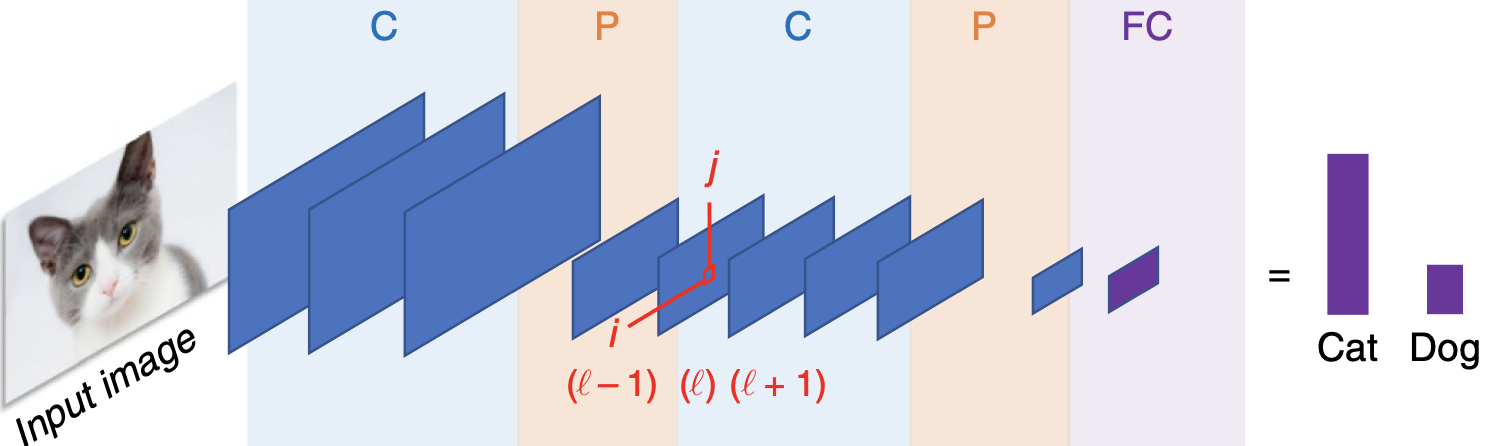
Figure 1. A schematic demonstration of the use of a CCNN to classify between images of a cat and dog. Here, we see the several convolutional and pooling layers being applied, all of which are decreasing in dimensionality due to the use of the pooling layers. The output of the CCNN determines whether the input image was a cat or dog. Image obtained form [1]. 

### 1.2 Quantum Convolutional Neural Networks 

Quantum Convolutional Neural Networks (QCNN) behave in a similar manner to CCNNs. First, we encode our pixelated image into a quantum circuit using a given feature map, such Qiskit's ZFeatureMap or ZZFeatureMap or others available in the circuit library.

After encoding our image, we apply alternating convolutional and pooling layers, as defined in the next section. By applying these alternating layers, we reduce the dimensionality of our circuit until we are left with one qubit. We can then classify our input image by measuring the output of this one remaining qubit.

The Quantum Convolutional Layer will consist of a series of two qubit unitary operators, which recognize and determine relationships between the qubits in our circuit. This unitary gates are defined below in the next section. 

For the Quantum Pooling Layer, we cannot do the same as is done classically to reduce the dimension, i.e. the number of qubits in our circuit. Instead, we reduce the number of qubits by performing operations upon each until a specific point and then disregard certain qubits in a specific layer. It is these layers where we stop performing operations on certain qubits that we call our 'pooling layer'. Details of the pooling layer is discussed further in the next section.

In the QCNN, each layer contains parametrized circuits, meaning we alter our output result by adjusting the parameters of each layer. When training our QCNN, it is these parameters that are adjusted to reduce the loss function of our QCNN. 

A simple example of four qubit QCNN can be seen below. 

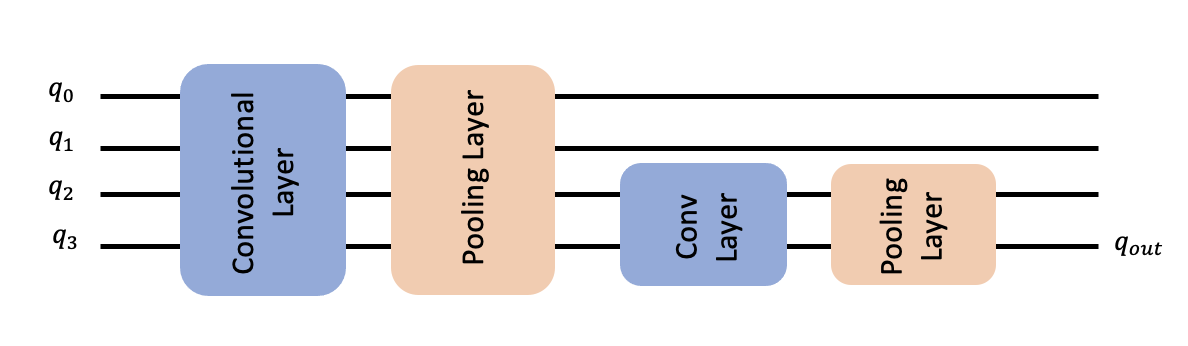


Figure 2: Example QCNN containing four qubits. The first Convolutional Layer acts on all the qubits. This is followed by the first pooling layer, which reduces the dimensionality of the QCNN from four qubits to two qubits by disregarding the first two. The second Convolutional layer then detects features between the two qubits still in use in the QCNN, followed by another pooling layer, which reduces the dimensionality from two qubits to one, which will be our output qubit.

## 2. Components of a QCNN

As discussed in Section 1 of this tutorial, a CCNN will contain both convolutional and pooling layers. Here, we define these layers for the QCNN in terms of gates applied to a Quantum Circuit and demonstrate an example for each layer for 4 qubits. 

Each of these layers will contain parameters which are tuned throughout the training process to minimize the loss function and train the QCNN to classify between horizontal and vertical lines. 

In theory, one could apply any parametrized circuit for both the convolutional and pooling layers of our network. For example in [2], the Gellmann Matrices (which are the three dimensional generalization of the Pauli Matrices) are used as generators for each unitary gate acting on a pair of qubits. 

Here, we take a different approach and form our parametrized circuit based on the two qubit unitary as proposed in [3]. This states that every unitary matrix in $U(4)$ can be decomposed such that 

$$U = (A_1 \otimes A_2) \cdot N(\alpha, \beta, \gamma) \cdot (A_3 \otimes A_4)$$

where $A_j \in \text{SU}(2)$, $\otimes$ is the tensor product, and $N(\alpha, \beta, \gamma) = exp(i[\alpha \sigma_x\sigma_x + \beta \sigma_y\sigma_y + \gamma \sigma_z\sigma_z ])$, where $\alpha, \beta, \gamma$ are the parameters that we can adjust. 

From this, it is evident that each unitary depends on 15 parameters and implies that in order for the QCNN to be able to span the whole Hilbert space, each unitary in our QCNN must contain 15 parameters each. 

Tuning this large amount of parameters would be difficult and would lead to long training times. To overcome this problem, we restrict our ansatz to a particular subspace of the Hilbert space and define the two qubit unitary gate as $N(\alpha, \beta, \gamma)$. These two qubit unitaries, as seen in [3] can be seen below and are applied to all neighboring qubits each of the layers in the QCNN. 

Note that by only using $N(\alpha, \beta, \gamma)$ as our two qubit unitary for the parametrized layers, we are restricting our QCNN to a particular subspace, one in which the optimal solution may not be contained in and reducing the accuracy of the QCNN. For the purpose of this tutorial, we will use this parametrized circuit to decrease the training time of our QCNN.

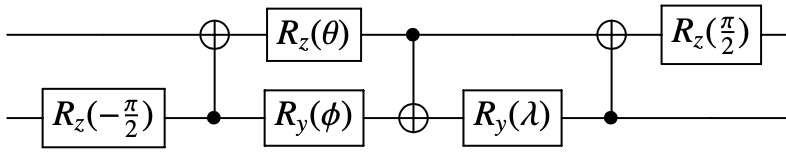

Figure 3:
Parametrized two qubit unitary circuit for $N(\alpha, \beta, \gamma) = exp(i[\alpha \sigma_x\sigma_x + \beta \sigma_y\sigma_y + \gamma \sigma_z\sigma_z ])$ as seen in [3], where $\alpha =  \frac{\pi}{2} - 2\theta$, $\beta = 2\phi - \frac{\pi}{2}$ and $\gamma =  \frac{\pi}{2} - 2\lambda$ as seen in the circuit. This two qubit unitary will be applied to all neighboring qubits in our feature map. 

### 2.1 Convolutional Layer

The next step in this tutorial is to define the Convolutional Layers of our QCNN. These layers are then applied to the qubits after the data has been encoded through use of the feature map. 

To do so we first need to determine a parametrized unitary gate, which will be used to create our convolutional and pooling layers. 

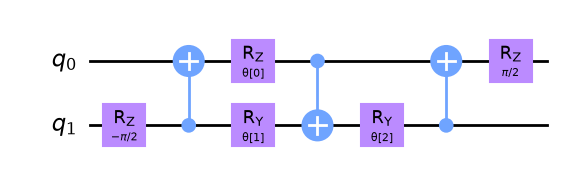

↑ the convolution block: 3 CNOTs and 3 trainable angles θ[0..2]; the fixed Rz(±π/2) complete the Vatan–Williams template for N(α, β, γ)
trainable parameters of one block: 3


In [2]:
# We now define a two qubit unitary as defined in [3]
def conv_circuit(params):                 # params: 3 angles (numbers or Parameters) -> a 2-qubit circuit
    target = QuantumCircuit(2)            # QuantumCircuit(2): two qubits, no classical bits
    target.rz(-np.pi / 2, 1)              # fixed Rz(-π/2) on qubit 1 (part of the Vatan-Williams template)
    target.cx(1, 0)                       # CNOT, control 1 -> target 0 (1st of 3 CNOTs)
    target.rz(params[0], 0)               # trainable angle θ0 on qubit 0
    target.ry(params[1], 1)               # trainable angle θ1 on qubit 1
    target.cx(0, 1)                       # CNOT, control 0 -> target 1 (2nd)
    target.ry(params[2], 1)               # trainable angle θ2 on qubit 1
    target.cx(1, 0)                       # CNOT, control 1 -> target 0 (3rd)
    target.rz(np.pi / 2, 0)               # fixed Rz(π/2) on qubit 0 closes the template
    return target


# Let's draw this circuit and see what it looks like
params = ParameterVector("θ", length=3)   # three symbols θ[0], θ[1], θ[2]
circuit = conv_circuit(params)            # the block with symbolic angles (still unbound)
display(draw(circuit)); print("↑ the convolution block: 3 CNOTs and 3 trainable angles θ[0..2]; the fixed Rz(±π/2) complete the Vatan–Williams template for N(α, β, γ)")
print("trainable parameters of one block:", circuit.num_parameters)   # .num_parameters counts the unbound Parameters


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `def conv_circuit(params)` | a Python function that *returns* a circuit: called once per qubit pair, each time with its own 3 angles |
| `target.rz(θ, q)`, `target.ry(θ, q)` | single-qubit rotations about z and y; with a `Parameter` as angle they stay symbolic until values are bound |
| three `cx` | the entangling part: 3 CNOTs are enough for *any* 2-qubit unitary (Vatan–Williams); here they produce the non-local core N(α, β, γ) whose 3 coordinates are set by θ[0..2] |
| `ParameterVector("θ", length=3)` | symbols θ[0], θ[1], θ[2] used only to draw the block |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Three parameters per block.** A general $U\in U(4)$ has $16$ real parameters ($15$ up to a global phase); by the
Vatan–Williams decomposition $U = (A_1\otimes A_2)\,N(\alpha,\beta,\gamma)\,(A_3\otimes A_4)$, $12$ of them sit in the
single-qubit gates $A_j$ and only $3$ in the entangling core
$N(\alpha,\beta,\gamma)=\exp\!\big(i[\alpha\,XX+\beta\,YY+\gamma\,ZZ]\big)$. The tutorial keeps just the core, so each block has
$3$ trainable angles. With Qiskit's convention $R_z(\theta)=e^{-i\theta Z/2}$, a numerical (Weyl) decomposition of the block gives

$$(\alpha,\beta,\gamma)=\Big(\tfrac{\pi}{4}-\tfrac{\theta_0}{2},\ \tfrac{\pi}{4}-\tfrac{\theta_1}{2},\ \tfrac{\theta_2}{2}-\tfrac{\pi}{4}\Big)$$

up to single-qubit gates (the figure caption above uses another normalisation of the angles); task 1 of the In-depth analysis checks it.
The cell prints `trainable parameters of one block: 3`.

</details>


Now that we have defined these unitaries, it is time to create a function for the convolutional layer in our QCNN. To do so, we apply the two qubit unitary to neighboring qubits as seen in the ``conv_layer`` function below.

Note that we first apply the two qubit unitary to all even pairs of qubits followed by applying to odd pairs of qubits in a circular coupling manner, i.e. the as well as neighboring qubits being coupled, the first and final qubit are also coupled through a unitary gate.

Note that we add barriers into our quantum circuits for convenience when plotting, however they are not required for the actual QCNN and can be extracted from the following circuits.

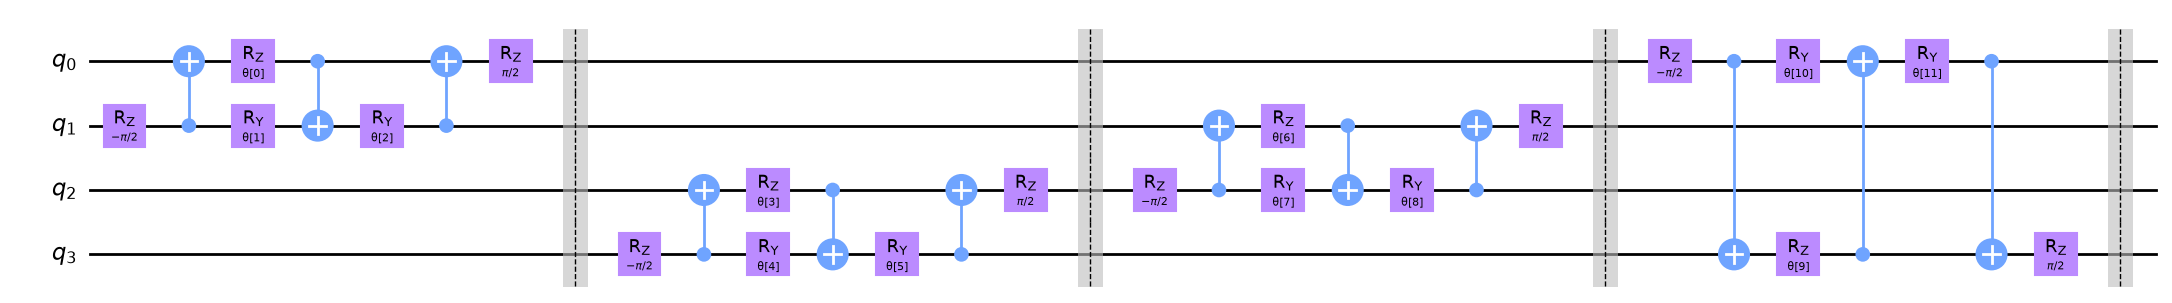

↑ convolutional layer on 4 qubits (decomposed): blocks on the even pairs (0,1), (2,3), then on the odd pairs (1,2), (3,0) — the last one closes the ring
parameters of conv_layer(4): 12


In [3]:
def conv_layer(num_qubits, param_prefix):
    qc = QuantumCircuit(num_qubits, name="Convolutional Layer")   # name= is the label of the box when drawn as one block
    qubits = list(range(num_qubits))
    param_index = 0                                               # position of the next unused angle
    params = ParameterVector(param_prefix, length=num_qubits * 3) # 3 angles per block, num_qubits blocks (see the box below)
    for q1, q2 in zip(qubits[0::2], qubits[1::2]):                # even pairs (0,1), (2,3), ... ; [0::2] = every second element from 0
        qc = qc.compose(conv_circuit(params[param_index : (param_index + 3)]), [q1, q2])   # compose(block, [q1, q2]): place the block on these qubits
        qc.barrier()                                              # visual separator only
        param_index += 3
    for q1, q2 in zip(qubits[1::2], qubits[2::2] + [0]):          # odd pairs (1,2), (3,4), ..., (n-1, 0): circular coupling
        qc = qc.compose(conv_circuit(params[param_index : (param_index + 3)]), [q1, q2])
        qc.barrier()
        param_index += 3

    qc_inst = qc.to_instruction()                                 # freeze the layer into one instruction (one box in drawings)

    qc = QuantumCircuit(num_qubits)
    qc.append(qc_inst, qubits)                                    # a circuit containing just that box
    return qc


circuit = conv_layer(4, "θ")                                      # an example layer on 4 qubits
display(draw(circuit.decompose())); print("↑ convolutional layer on 4 qubits (decomposed): blocks on the even pairs (0,1), (2,3), then on the odd pairs (1,2), (3,0) — the last one closes the ring")
print("parameters of conv_layer(4):", circuit.num_parameters)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `zip(qubits[0::2], qubits[1::2])` | slicing `[start::step]` + `zip`: pairs (0,1), (2,3), ... — the first sub-layer of blocks, all acting in parallel |
| `zip(qubits[1::2], qubits[2::2] + [0])` | pairs (1,2), (3,4), ..., (n−1, 0): the second sub-layer, shifted by one and wrapped around (periodic boundary, like a convolution kernel sliding over a ring) |
| `params[i : i + 3]` | a slice of the ParameterVector: each block gets its own 3 angles, so no weight is shared between blocks (unlike a classical convolution kernel) |
| `qc.to_instruction()` + `append` | packs the whole layer into one named gate; `.decompose()` opens it again for the drawing |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Parameters of a convolutional layer.** On $n$ qubits (even $n$) the even sub-layer has $n/2$ pairs $(0,1),(2,3),\dots$ and the
odd sub-layer another $n/2$ pairs $(1,2),\dots,(n-1,0)$: $n$ blocks of $3$ angles,

$$P_{\rm conv}(n) = 3n:\qquad P_{\rm conv}(4)=12,\quad P_{\rm conv}(8)=24,\quad P_{\rm conv}(2)=6 .$$

(For $n=2$ the two "pairs" are $(0,1)$ and $(1,0)$: the same two qubits, with the roles swapped.) The cell prints
`parameters of conv_layer(4): 12`.

</details>


### 2.2 Pooling Layer

The purpose of a pooling layer is to reduce the dimensions of our Quantum Circuit, i.e. reduce the number of qubits in our circuit, while retaining as much information as possible from previously learned data. Reducing the amount of qubits also reduces the computational cost of the overall circuit, as the number of parameters that the QCNN needs to learn decreases. 

However, one cannot simply decrease the amount of qubits in our quantum circuit. Because of this, we must define the pooling layer in a different manner compared with the classical approach. 

To 'artificially' reduce the number of qubits in our circuit, we first begin by creating pairs of the $N$ qubits in our system. 

After initially pairing all the qubits, we apply our generalized 2 qubit unitary to each pair, as described previously. After applying this two qubit unitary, we then ignore one qubit from each pair of qubits for the remainder of the neural network. 

This layer therefore has the overall effect of 'combining' the information of the two qubits into one qubit by first applying the unitary circuit, encoding information from one qubit into another, before disregarding one of qubits for the remainder of the circuit and not performing any operations or measurements on it. 

We note that one could also apply a dynamic circuit to reduce the dimensionality in the pooling layers. This would involve performing measurements on certain qubits in the circuit and having an intermediate classical feedback loop in our pooling layers. By applying these measurements, one would also be reducing the dimensionality of the circuit. 

In this tutorial, we apply the former approach, and disregard qubits in each pooling layer. Using this approach, we thus create a QCNN Pooling Layer which transforms the dimensions of our $N$ qubit Quantum Circuit to $N/2$. 

To do so, we first define a two qubit unitary, which transforms the two qubit system to one. 


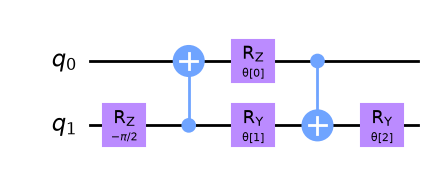

↑ the pooling block: 2 CNOTs and 3 angles; afterwards qubit 0 (source) is left alone and only qubit 1 (sink) continues


In [4]:
def pool_circuit(params):                 # the pooling block: the first 6 gates of conv_circuit
    target = QuantumCircuit(2)
    target.rz(-np.pi / 2, 1)
    target.cx(1, 0)
    target.rz(params[0], 0)               # trainable θ0
    target.ry(params[1], 1)               # trainable θ1
    target.cx(0, 1)                       # control 0 (the qubit dropped afterwards) -> target 1 (the qubit kept)
    target.ry(params[2], 1)               # trainable θ2 on the kept qubit

    return target


params = ParameterVector("θ", length=3)
circuit = pool_circuit(params)
display(draw(circuit)); print("↑ the pooling block: 2 CNOTs and 3 angles; afterwards qubit 0 (source) is left alone and only qubit 1 (sink) continues")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `pool_circuit(params)` | the convolution block without its last CNOT and Rz: it ends with a rotation on qubit 1, the qubit that survives |
| `cx(0, 1)` then `ry(θ2, 1)` | information of the source qubit 0 is copied (controlled) into the sink qubit 1 and processed there — 'combining two qubits into one' |
| no measurement / reset | pooling here is *not* a measurement: the source qubit is simply never used again (it is traced out at the end) |

</details>


After applying this two qubit unitary circuit, we neglect the first qubit (q0) in future layers and only use the second qubit (q1) in our QCNN

We apply this two qubit pooling layer to different pairs of qubits to create our pooling layer for N qubits. As an example we then plot it for four qubits. 

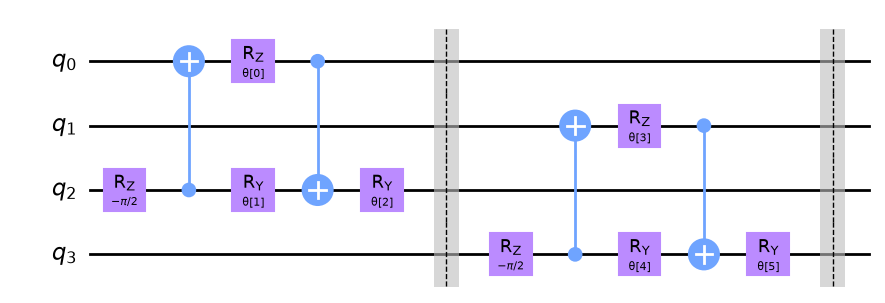

↑ pooling layer 4 → 2 (decomposed): blocks on (0→2) and (1→3); after it only qubits 2 and 3 are used
parameters of pool_layer([0, 1], [2, 3]): 6


In [5]:
def pool_layer(sources, sinks, param_prefix):
    num_qubits = len(sources) + len(sinks)                        # e.g. 2 sources + 2 sinks = 4 qubits
    qc = QuantumCircuit(num_qubits, name="Pooling Layer")
    param_index = 0
    params = ParameterVector(param_prefix, length=num_qubits // 2 * 3)   # // = integer division: 3 angles per (source, sink) pair
    for source, sink in zip(sources, sinks):                      # pair the i-th source with the i-th sink
        qc = qc.compose(pool_circuit(params[param_index : (param_index + 3)]), [source, sink])
        qc.barrier()
        param_index += 3

    qc_inst = qc.to_instruction()                                 # one named box, as for the conv layer

    qc = QuantumCircuit(num_qubits)
    qc.append(qc_inst, range(num_qubits))
    return qc


sources = [0, 1]                          # qubits that will be dropped
sinks = [2, 3]                            # qubits that carry on to the next layer
circuit = pool_layer(sources, sinks, "θ")
display(draw(circuit.decompose())); print("↑ pooling layer 4 → 2 (decomposed): blocks on (0→2) and (1→3); after it only qubits 2 and 3 are used")
print("parameters of pool_layer([0, 1], [2, 3]):", circuit.num_parameters)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `pool_layer(sources, sinks, prefix)` | one pooling block per (source, sink) pair: the sources are discarded, the sinks are the input of the next layer |
| `num_qubits // 2 * 3` | 3 angles per pair and n/2 pairs: 3n/2 parameters (6 for n = 4) |
| `range(num_qubits)` | the layer acts on *local* indices 0..n−1; when it is placed in the 8-qubit ansatz, `compose(..., list(range(4, 8)))` maps them to the real qubits |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Parameters of a pooling layer.** $n$ qubits form $n/2$ (source, sink) pairs, one 3-angle block each:

$$P_{\rm pool}(n)=3\cdot\frac{n}{2}:\qquad P_{\rm pool}(4)=6,\quad P_{\rm pool}(8)=12,\quad P_{\rm pool}(2)=3,$$

and the layer leaves $n/2$ active qubits. The cell prints `parameters of pool_layer([0, 1], [2, 3]): 6`.

</details>


In this particular example, we reduce the dimensionality of our four qubit circuit to the last two qubits, i.e. the last two qubits in this particular example. These qubits are then used in the next layer, while the first two are neglected for the remainder of the QCNN. 

## 3. Data Generation

One common use of a CCNN is an image classifier, where a CCNN detects particular features and patterns (such as straight lines or curves) of the pixelated images through the use of the feature maps in the convolutional layer. By learning the relationship between these features, it can then classify and label handwritten digits with ease. 

Because of a classical CNN's ability to recognize features and patterns easily, we will train our QCNN to also determine patterns and features of a given set of pixelated images, and classify between two different patterns. 

To simplify the dataset, we only consider 2 x 4 pixelated images. The patterns we will train the QCNN to distinguish will be a horizontal or vertical line, which can be placed anywhere in the image, alongside a noisy background. 

We first begin by generating this dataset. To create a 'horizontal' or 'vertical' line, we assign pixels value to be $\frac{\pi}{2}$ which will represent the line in our pixelated image. We create a noisy background by assigning every other pixel a random value between $0$ and $\frac{\pi}{4}$ which will create a noisy background. 

Note that when we create our dataset, we need to split it into the training set and testing set of images, the datasets we train and test our neural network respectively.

We also need to label our datasets such that the QCNN can learn to differentiate between the two patterns. In this example we label images with a horizontal line with -1 and images with a vertical line +1.

In [6]:
def generate_dataset(num_images):
    images = []                                   # list of 8-pixel images (NumPy arrays)
    labels = []                                   # -1 = horizontal line, +1 = vertical line
    hor_array = np.zeros((6, 8))                  # the 6 possible horizontal lines (one per row of the array)
    ver_array = np.zeros((4, 8))                  # the 4 possible vertical lines

    j = 0
    for i in range(0, 7):
        if i != 3:                                # skip i = 3: pixels 3 and 4 are in different rows of the 2x4 image
            hor_array[j][i] = np.pi / 2           # two adjacent pixels in the same row = a horizontal segment
            hor_array[j][i + 1] = np.pi / 2
            j += 1

    j = 0
    for i in range(0, 4):
        ver_array[j][i] = np.pi / 2               # pixel i (top row) and pixel i + 4 (bottom row, same column)
        ver_array[j][i + 4] = np.pi / 2
        j += 1

    for n in range(num_images):
        rng = algorithm_globals.random.integers(0, 2)            # 0 or 1 with equal probability: which kind of line
        if rng == 0:
            labels.append(-1)
            random_image = algorithm_globals.random.integers(0, 6)   # one of the 6 horizontal positions
            images.append(np.array(hor_array[random_image]))      # np.array(...) makes a copy, so the noise below does not touch hor_array
        elif rng == 1:
            labels.append(1)
            random_image = algorithm_globals.random.integers(0, 4)   # one of the 4 vertical positions
            images.append(np.array(ver_array[random_image]))

        # Create noise
        for i in range(8):
            if images[-1][i] == 0:                                    # images[-1] = the image just appended; 0 = background pixel
                images[-1][i] = algorithm_globals.random.uniform(0, np.pi / 4)   # background: uniform noise in [0, π/4]
    return images, labels


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `np.zeros((6, 8))`, `hor_array[j][i] = np.pi / 2` | a table of the 6 horizontal and 4 vertical line templates; a pixel is an *angle*: π/2 on the line, 0 elsewhere |
| `if i != 3` | pixel k of the 8-vector sits at row k // 4, column k % 4 of the 2×4 image; pixels 3 and 4 are not neighbours in a row, so that pair is skipped |
| `algorithm_globals.random.integers` / `.uniform` | the seeded NumPy generator of the library: label, line position and background noise in [0, π/4] are all reproducible |
| `images[-1]` | negative index: the last element of the list |

</details>


Let's now create our dataset below and split it into our test and training datasets. We pass a `random_state` so the split will be the same each time this notebook is run so the final results do not vary.

In [7]:
images, labels = generate_dataset(50)       # 50 random images with their labels

train_images, test_images, train_labels, test_labels = train_test_split(
    images, labels, test_size=0.3, random_state=246   # 30 % of the images go to the test set; random_state fixes the shuffle
)
print(f"{len(train_images)} training images, {len(test_images)} test images")
print("label counts in the training set (-1 horizontal, +1 vertical):", {int(v): train_labels.count(v) for v in (-1, 1)})   # dict comprehension


35 training images, 15 test images
label counts in the training set (-1 horizontal, +1 vertical): {-1: 16, 1: 19}


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `train_test_split(..., test_size=0.3, random_state=246)` | scikit-learn: shuffles and splits the 50 images into 35 for training and 15 for testing, the same way on every run |
| `train_labels.count(v)` | list method: how many times v occurs — checks that both classes are well represented |

</details>


Let's see some examples in our dataset

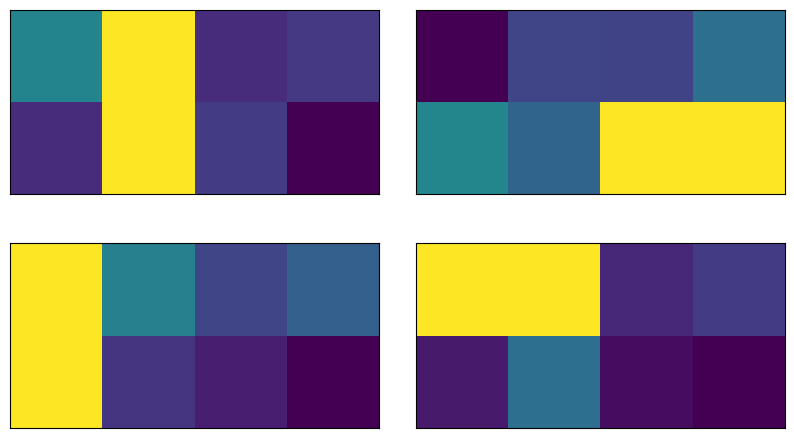

↑ four training images (8-vector reshaped to 2×4): the bright pixels (π/2) form the line, the dark ones are background noise in [0, π/4]
their labels: [1, -1, 1, -1]


In [8]:
fig, ax = plt.subplots(2, 2, figsize=(10, 6), subplot_kw={"xticks": [], "yticks": []})   # a 2x2 grid of axes without ticks
for i in range(4):
    ax[i // 2, i % 2].imshow(                     # ax[row, col]: i // 2 and i % 2 walk through the grid
        train_images[i].reshape(2, 4),  # Change back to 2 by 4
        aspect="equal",
    )
plt.subplots_adjust(wspace=0.1, hspace=0.025)
plt.show()
print("↑ four training images (8-vector reshaped to 2×4): the bright pixels (π/2) form the line, the dark ones are background noise in [0, π/4]")
print("their labels:", train_labels[:4])


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `train_images[i].reshape(2, 4)` | turn the 8-vector back into the 2×4 picture: pixels 0–3 are the top row, 4–7 the bottom row |
| `imshow` | draws an array as an image, colour = value: the line (π/2) is bright, the noise (≤ π/4) dark |
| `train_labels[:4]` | −1 = horizontal, +1 = vertical: compare with the pictures |

</details>


As we can see each image contains either a vertical or horizontal line, that the QCNN will learn how to differentiate. Now that we have built our dataset, it is time to discuss the components of the QCNN and build our model.

## 4. Modeling our QCNN

Now that we have defined both the convolutional layers it is now time to build our QCNN, which will consist of alternating pooling and convolutional layers.

As the images in our dataset contains 8 pixels, we will use 8 qubits in our QCNN. 

We encode our dataset into our QCNN by applying a feature map. One can create a feature map using one of Qiskit's built in feature maps, such as ZFeatureMap or ZZFeatureMap. 

After analyzing several different Feature maps for this dataset, it was found that QCNN obtains the greatest accuracy when the Z feature map is used. Therefore, throughout the remainder of the tutorial we will use the Z feature Map, of which can be seen below. 

/tmp/ipykernel_754326/4008932483.py:1: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._z_feature_map.ZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the z_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZFeatureMap(8)                        # 8 qubits, one input parameter x[k] per pixel, reps = 2 by default


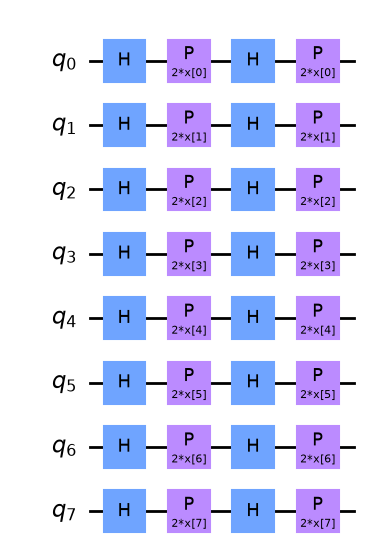

↑ ZFeatureMap(8) (decomposed): H then P(2·x[k]) on every qubit, the whole layer repeated twice — no entangling gates
pixel value 1.5708 -> P(qubit = 1) = 1.0000
pixel value 0.7854 -> P(qubit = 1) = 0.5000
pixel value 0.3927 -> P(qubit = 1) = 0.1464


In [9]:
feature_map = ZFeatureMap(8)                        # 8 qubits, one input parameter x[k] per pixel, reps = 2 by default
display(draw(feature_map.decompose())); print("↑ ZFeatureMap(8) (decomposed): H then P(2·x[k]) on every qubit, the whole layer repeated twice — no entangling gates")

from qiskit.quantum_info import Statevector         # exact state vector: used here to check what the encoding does to one pixel
for x_pix in (np.pi / 2, np.pi / 4, np.pi / 8):     # a line pixel, the largest noise, a typical noise value
    p1 = Statevector(feature_map.assign_parameters([x_pix] * 8)).probabilities([0])[1]   # P(qubit 0 = 1) after the feature map
    print(f"pixel value {x_pix:.4f} -> P(qubit = 1) = {p1:.4f}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `ZFeatureMap(8)` | the data-encoding layer: pixel k sets the phase gate P(2·x[k]) on qubit k, sandwiched between Hadamards; the two repetitions turn the phase into a population (box below) |
| `.decompose()` | opens the library block into its H and P gates for the drawing |
| `assign_parameters([x] * 8)` | binds the 8 input parameters to numbers (here all equal to x) to obtain a concrete circuit |
| `Statevector(...).probabilities([0])` | marginal probabilities of qubit 0 alone: [P(0), P(1)] |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**What the Z feature map does to one pixel.** On each qubit: $H$, $P(\varphi)$, $H$, $P(\varphi)$ with $\varphi = 2x$. After
the first $H\,P(\varphi)$ the qubit is $\tfrac{1}{\sqrt2}(|0\rangle + e^{i\varphi}|1\rangle)$; the second $H$ gives

$$\tfrac12\big[(1+e^{i\varphi})|0\rangle + (1-e^{i\varphi})|1\rangle\big]
\;\Rightarrow\; P(1)=\frac{|1-e^{i\varphi}|^2}{4}=\sin^2\frac{\varphi}{2}=\sin^2 x ,$$

and the last $P(\varphi)$ only changes a phase. So a line pixel ($x=\pi/2$) becomes $|1\rangle$ with certainty, while background
noise ($x\le\pi/4$) gives $P(1)\le \sin^2(\pi/4)=0.5$: $\sin^2(\pi/8)=0.1464$. The cell prints
`1.0000`, `0.5000`, `0.1464`.

</details>


We create a function for our QCNN, which will contain three sets of alternating convolutional and pooling layers, which can be seen in the schematic below. Through the use of the pooling layers, we thus reduce the dimensionality of our QCNN from eight qubits to one. 

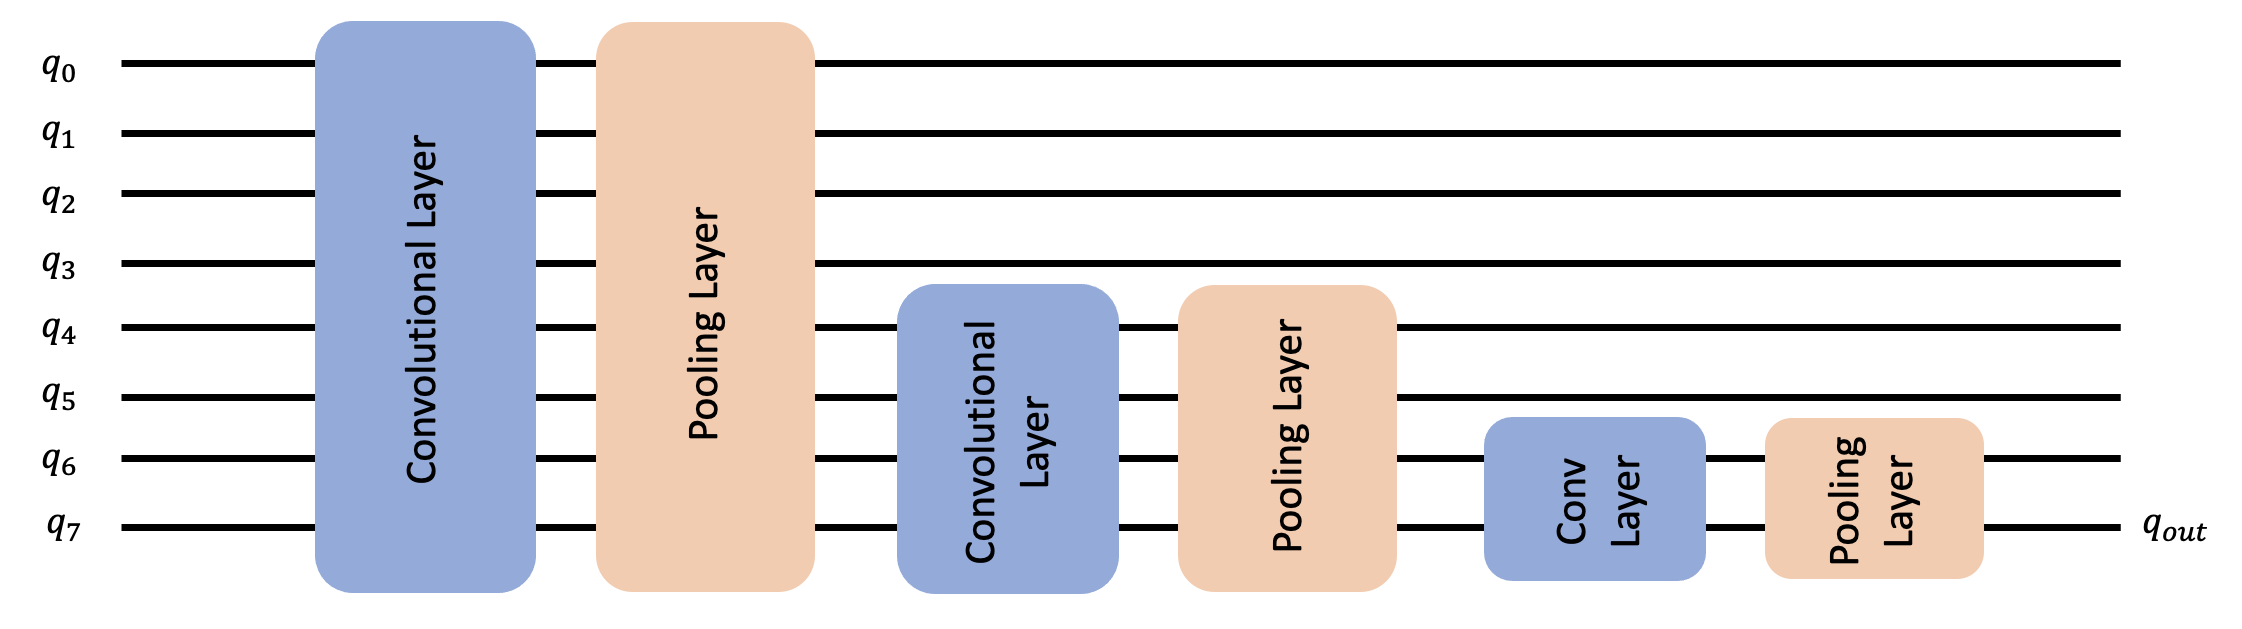

To classify our image dataset of horizontal and vertical lines, we measure the expectation value of the Pauli Z operator of the final qubit. Based on the obtained value being +1 or -1, we can conclude that the input image contained either a horizontal or vertical line. 

## 5. Training our QCNN

The next step is to build our model using our training data. 

To classify our system, we perform a measurement from the output circuit. The value we obtain will thus classify whether our input data contains either a vertical line or horizontal line. 

The measurement we have chosen in this tutorial is $<Z>$, i.e. the expectation value of the Pauli Z qubit for the final qubit. Measuring this expectation value, we obtain +1 or -1, which correspond to a vertical or horizontal line respectively. 

In [10]:
feature_map = ZFeatureMap(8)                        # the encoding of the 8 pixels (inputs of the network)

ansatz = QuantumCircuit(8, name="Ansatz")           # the trainable part (weights of the network)

# First Convolutional Layer
ansatz.compose(conv_layer(8, "c1"), list(range(8)), inplace=True)        # inplace=True modifies ansatz instead of returning a copy

# First Pooling Layer
ansatz.compose(pool_layer([0, 1, 2, 3], [4, 5, 6, 7], "p1"), list(range(8)), inplace=True)   # 8 -> 4: qubits 4..7 survive

# Second Convolutional Layer
ansatz.compose(conv_layer(4, "c2"), list(range(4, 8)), inplace=True)     # acts on qubits 4..7 only

# Second Pooling Layer
ansatz.compose(pool_layer([0, 1], [2, 3], "p2"), list(range(4, 8)), inplace=True)   # local (0,1)->(2,3) = qubits (4,5)->(6,7): 4 -> 2

# Third Convolutional Layer
ansatz.compose(conv_layer(2, "c3"), list(range(6, 8)), inplace=True)     # qubits 6, 7

# Third Pooling Layer
ansatz.compose(pool_layer([0], [1], "p3"), list(range(6, 8)), inplace=True)   # 6 -> 7: 2 -> 1, the readout qubit is 7

# Combining the feature map and ansatz
circuit = QuantumCircuit(8)
circuit.compose(feature_map, range(8), inplace=True)
circuit.compose(ansatz, range(8), inplace=True)

observable = SparsePauliOp.from_list([("Z" + "I" * 7, 1)])   # Pauli string "ZIIIIIII" with coefficient 1: Z on qubit 7 (labels read right to left)

# we decompose the circuit for the QNN to avoid additional data copying
qnn = EstimatorQNN(
    circuit=circuit.decompose(),                    # feature map + ansatz, opened into elementary gates
    observables=observable,                         # network output = <Z_7>
    input_params=feature_map.parameters,            # the 8 x[k]: filled with the pixels of each image
    weight_params=ansatz.parameters,                # the trainable angles: tuned by the optimizer
    estimator=estimator,                            # StatevectorEstimator
    default_precision=0.0,                          # exact values: the library default 1/64 makes StatevectorEstimator add random Gaussian "shot" noise (std 0.016) to every output
)
print(f"inputs: {qnn.num_inputs}, weights: {qnn.num_weights}, outputs: {qnn.output_shape}")
print({name: n for name, n in zip(("c1", "p1", "c2", "p2", "c3", "p3"),
       [sum(p.name.startswith(pre) for p in ansatz.parameters) for pre in ("c1", "p1", "c2", "p2", "c3", "p3")])})   # weights per layer


inputs: 8, weights: 63, outputs: (1,)
{'c1': 24, 'p1': 12, 'c2': 12, 'p2': 6, 'c3': 6, 'p3': 3}


/tmp/ipykernel_754326/2946470382.py:1: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._z_feature_map.ZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the z_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZFeatureMap(8)                        # the encoding of the 8 pixels (inputs of the network)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `ansatz.compose(layer, qubits, inplace=True)` | places each layer on the listed qubits of the 8-qubit ansatz; the qubit lists shrink 8 → 4 → 2 as the pooling layers discard qubits |
| `SparsePauliOp.from_list([("Z" + "I" * 7, 1)])` | the observable Z⊗I⊗…⊗I written as a label; Qiskit's rightmost character is qubit 0, so Z acts on qubit 7, the only qubit left after the last pooling |
| `EstimatorQNN(circuit=..., observables=..., input_params=..., weight_params=...)` | turns the circuit into a function f(x, w) = ⟨ψ(x, w)\|Z₇\|ψ(x, w)⟩ ∈ [−1, 1]; the input/weight split tells the library what the data are and what is trained |
| `default_precision=0.0` | EstimatorQNN asks the estimator for a precision of 1/64 by default, and StatevectorEstimator then *simulates* shot noise by adding unseeded Gaussian noise of that size: every run would train differently. Precision 0 gives exact, reproducible ⟨Z₇⟩ (as the V1 Estimator of the original tutorial did) |
| `p.name.startswith(pre)` | counts the Parameters of each layer by their prefix (c1, p1, …): a check of the box below |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Weights of the full ansatz.** Convolutions on $8, 4, 2$ qubits and poolings $8\to4$, $4\to2$, $2\to1$:

$$P = \underbrace{3\cdot8+3\cdot4+3\cdot2}_{\text{conv: }24+12+6\,=\,42} + \underbrace{3\cdot4+3\cdot2+3\cdot1}_{\text{pool: }12+6+3\,=\,21} = 63 .$$

**Qubits halved by each pooling layer, $8\to4\to2\to1$.** `p1` sends sources $0$–$3$ into sinks $4$–$7$; `c2` and `p2` act on
qubits $4$–$7$ (local $(0,1)\to(2,3)$ = qubits $(4,5)\to(6,7)$); `c3` and `p3` act on $6,7$, and `p3` sends $6\to7$.
After it only **qubit 7** is still processed; the others are never touched again (in the density-matrix picture they are traced out).

**The observable and the class.** $O=Z_7$, so the network output is
$f(x,w)=\langle Z_7\rangle = P(q_7=0)-P(q_7=1)\in[-1,1]$. The classifier predicts $\hat y=\operatorname{sign} f$:
$+1$ = vertical, $-1$ = horizontal (e.g. $f=0.6$ means $P(q_7=0)=0.8$: "vertical"). The value is exact here; on hardware it is
estimated from shots, $\langle Z\rangle\approx (n_0-n_1)/N_{\rm shots}$. The cell prints `inputs: 8, weights: 63` and the
per-layer counts `24, 12, 12, 6, 6, 3`.

</details>


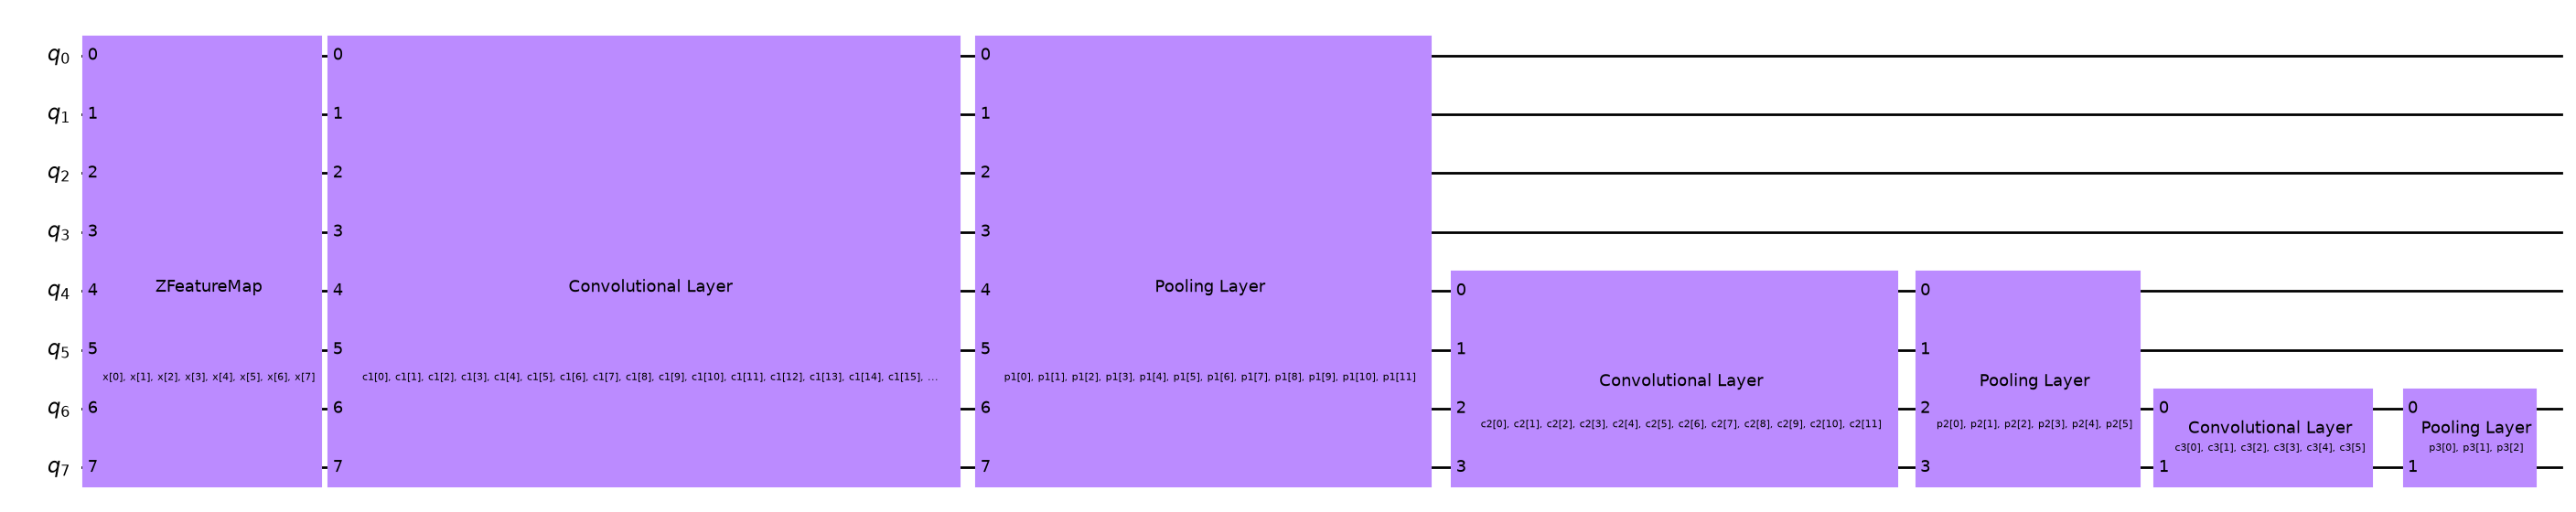

↑ the whole QCNN as blocks: ZFeatureMap (encoding) followed by the Ansatz (3 conv + 3 pool layers)


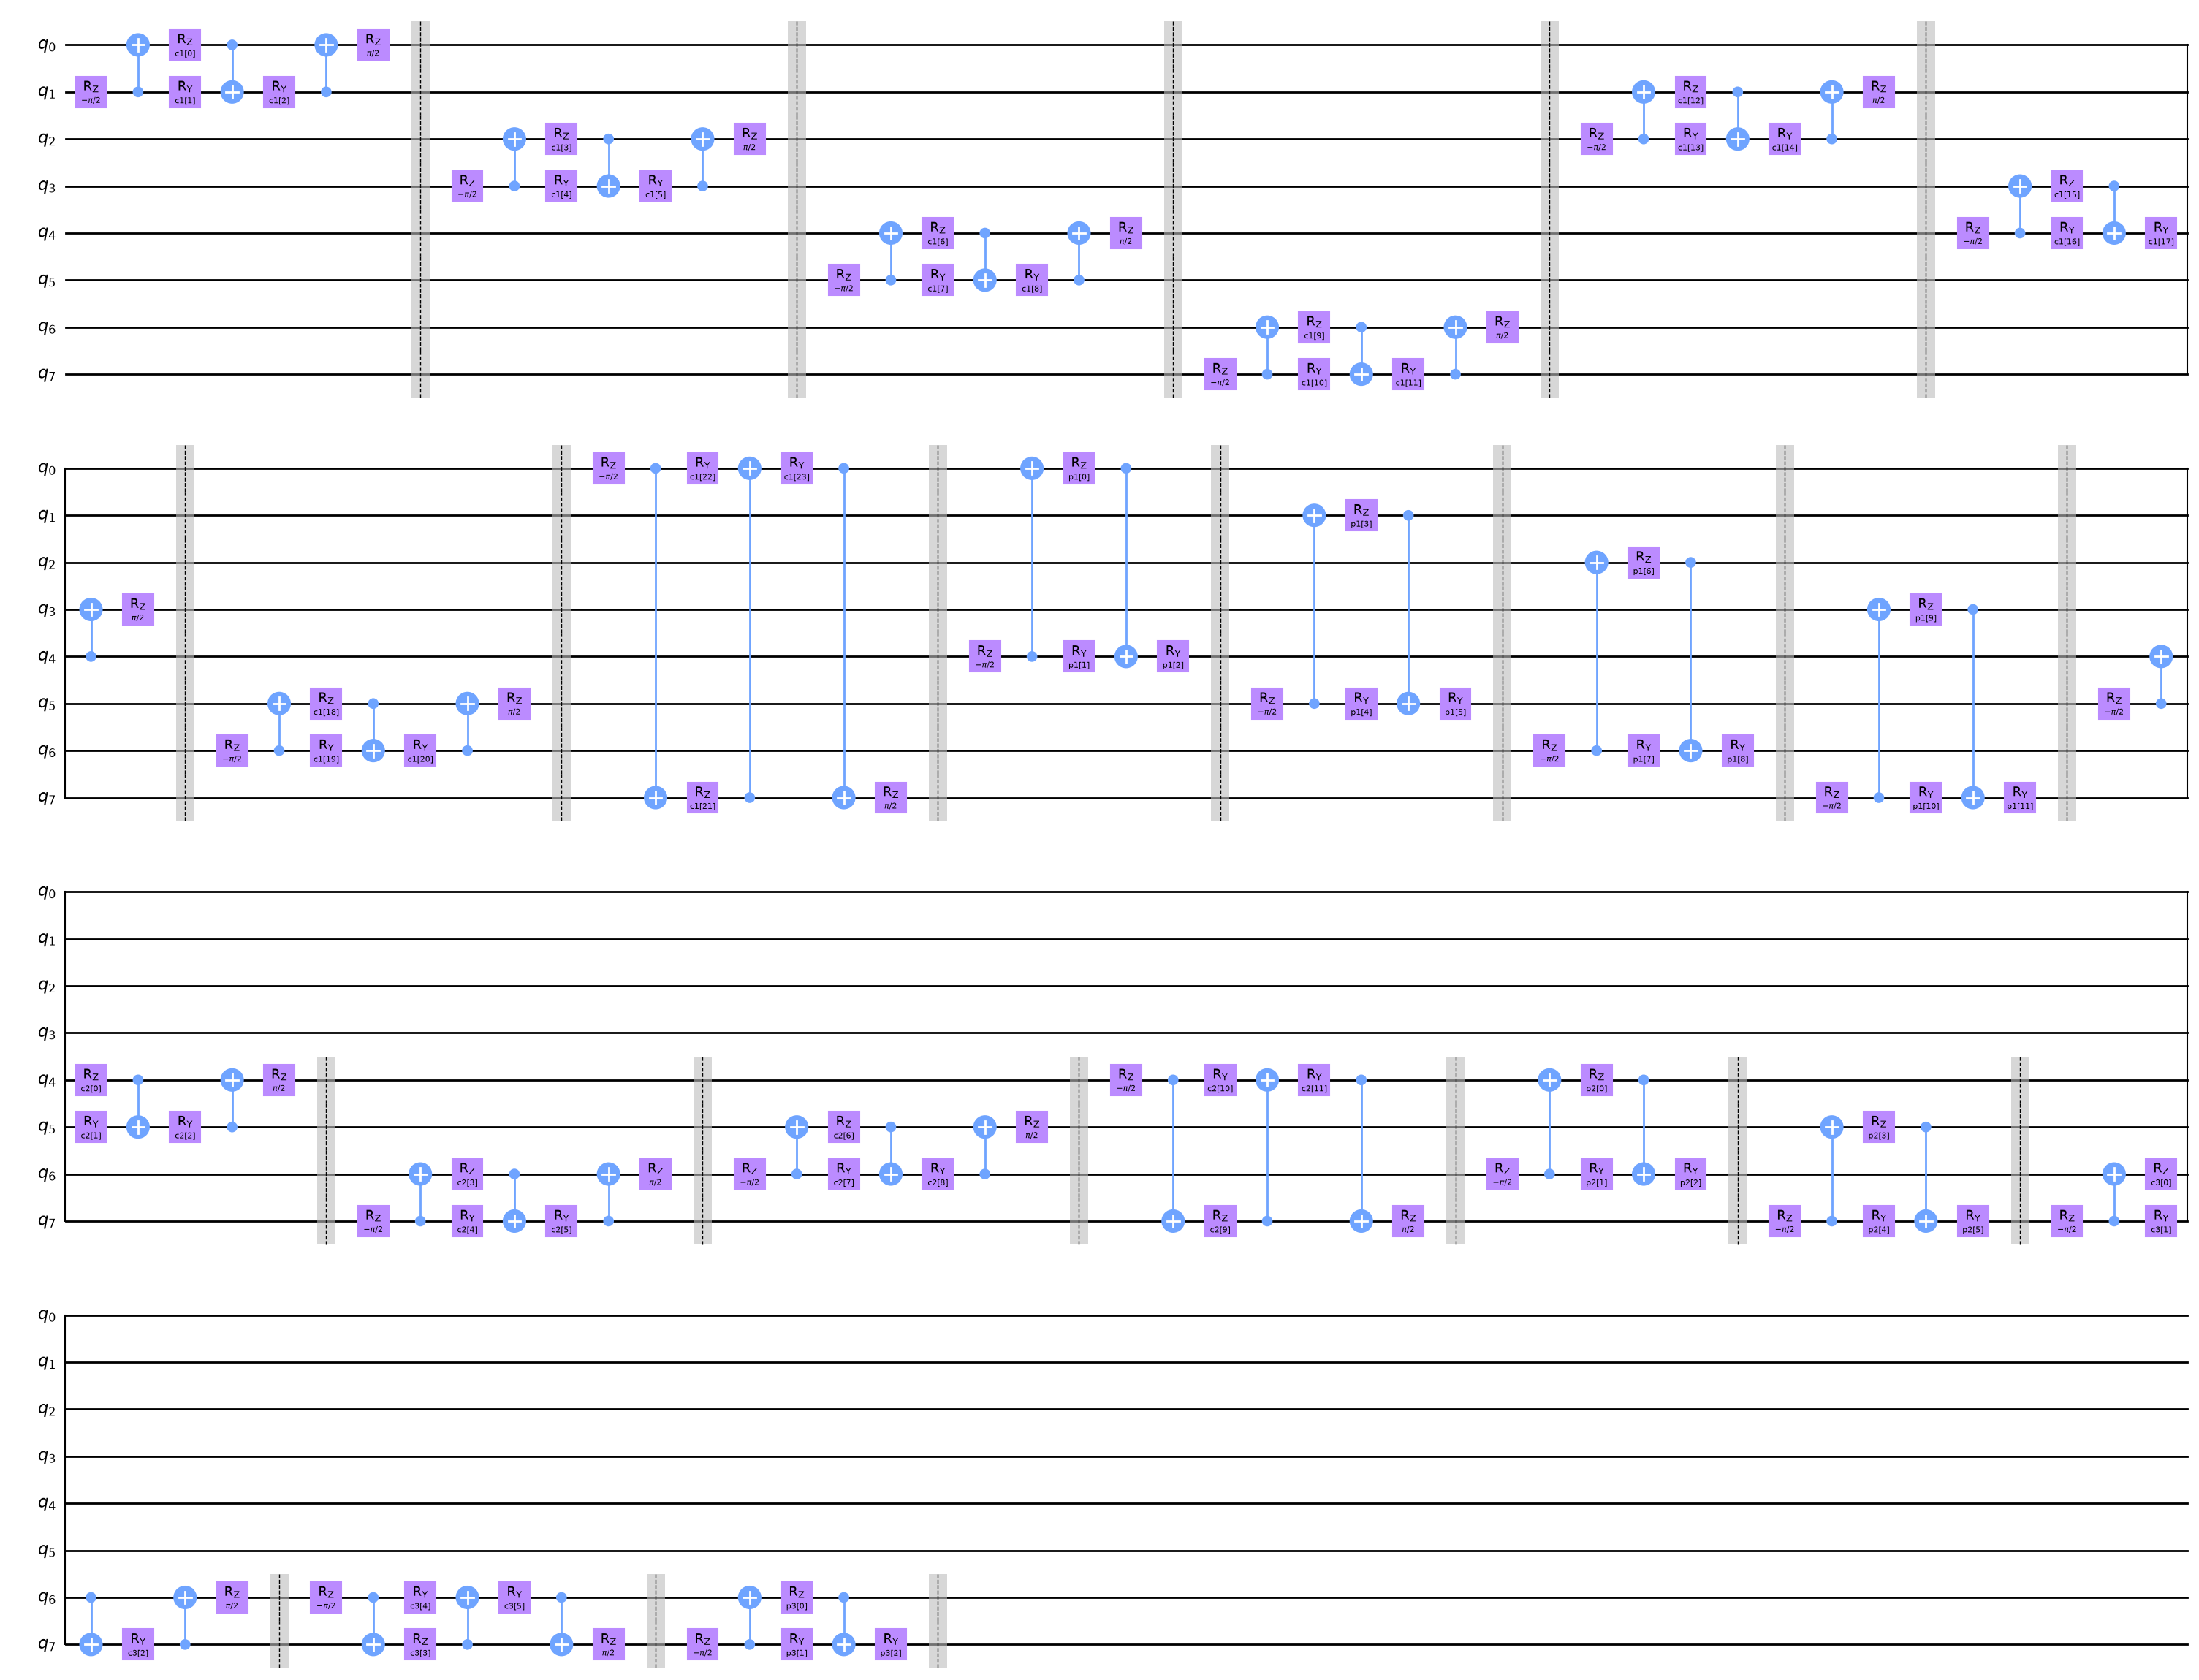

↑ the ansatz decomposed into its layers (barriers separate the blocks): conv on 8 qubits, pool 0-3 → 4-7, conv/pool on 4-7, conv/pool on 6-7 — the active region shrinks towards qubit 7
gates of the decomposed QCNN: {'rz': 56, 'cx': 56, 'ry': 42, 'barrier': 21, 'h': 16, 'p': 16} | depth: 137


In [11]:
display(draw(circuit)); print("↑ the whole QCNN as blocks: ZFeatureMap (encoding) followed by the Ansatz (3 conv + 3 pool layers)")
display(draw(ansatz.decompose(), fold=45)); print("↑ the ansatz decomposed into its layers (barriers separate the blocks): conv on 8 qubits, pool 0-3 → 4-7, conv/pool on 4-7, conv/pool on 6-7 — the active region shrinks towards qubit 7")
qnn_circ = circuit.decompose()                      # the circuit actually given to the EstimatorQNN
print("gates of the decomposed QCNN:", dict(qnn_circ.count_ops()), "| depth:", qnn_circ.depth())


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `draw(circuit)` | the top-level view: two boxes, the feature map and the ansatz |
| `draw(ansatz.decompose(), fold=45)` | one level down: every layer opened into its blocks, wrapped every 45 columns so the picture stays readable |
| `count_ops()`, `depth()` | gate census and number of time steps of the circuit evaluated for every image: 56 CNOTs (3 per conv block, 2 per pool block: 14·3 + 7·2 = 56) |

</details>


We will also define a callback function to use when training our model. This allows us to view and plot the loss function per each iteration in our training process.

In [12]:
def callback_graph(weights, obj_func_eval):          # called by the optimizer after every evaluation of the objective
    clear_output(wait=True)                         # wait=True: erase the old plot only when the new one is ready (no flicker)
    objective_func_vals.append(obj_func_eval)       # global list filled during training (created in the training cell)
    plt.title("Objective function value against iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Objective function value")
    plt.plot(range(len(objective_func_vals)), objective_func_vals)
    plt.show()


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `callback_graph(weights, obj_func_eval)` | the signature the classifier expects: current weights and current value of the loss |
| `clear_output(wait=True)` + `plt.show()` | redraws the training curve in the same output area at every iteration: a live plot |

</details>


In this example, we will use the COBYLA optimizer to train our classifier, which is a numerical optimization method commonly used for classification machine learning algorithms.

We then place the the callback function, optimizer and operator of our QCNN created above into Qiskit Machine Learning's built in Neural Network Classifier, which we can then use to train our model. 

Since model training may take a long time we have already pre-trained the model for some iterations and saved the pre-trained weights. We'll continue training from that point by setting `initial_point` to a vector of pre-trained weights.

In [13]:
with open("24_qcnn_initial_point.json", "r") as f:   # the pre-trained weights, in the same folder as this notebook
    initial_point = json.load(f)                    # a list of 63 numbers, one per weight

classifier = NeuralNetworkClassifier(
    qnn,
    optimizer=COBYLA(maxiter=200),  # Set max iterations here
    callback=callback_graph,                        # live training curve
    initial_point=initial_point,                    # start from the pre-trained weights instead of random ones
)
print("initial point:", len(initial_point), "weights")


initial point: 63 weights


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `with open(...) as f: json.load(f)` | reads the 63 pre-trained weights; `with` closes the file automatically. The file must be next to the notebook |
| `NeuralNetworkClassifier(qnn, optimizer=..., callback=..., initial_point=...)` | wraps the QNN in a scikit-learn-style classifier; default loss = squared error, prediction = sign of the output |
| `COBYLA(maxiter=200)` | gradient-free optimizer: at most 200 evaluations of the loss (each = 35 circuit evaluations, one per training image) |

</details>


After creating this classifier, we can train our QCNN using our training dataset and each image's corresponding label. Because we previously defined the callback function, we plot the overall loss of our system per iteration.

It may take some time to train the QCNN so be patient!

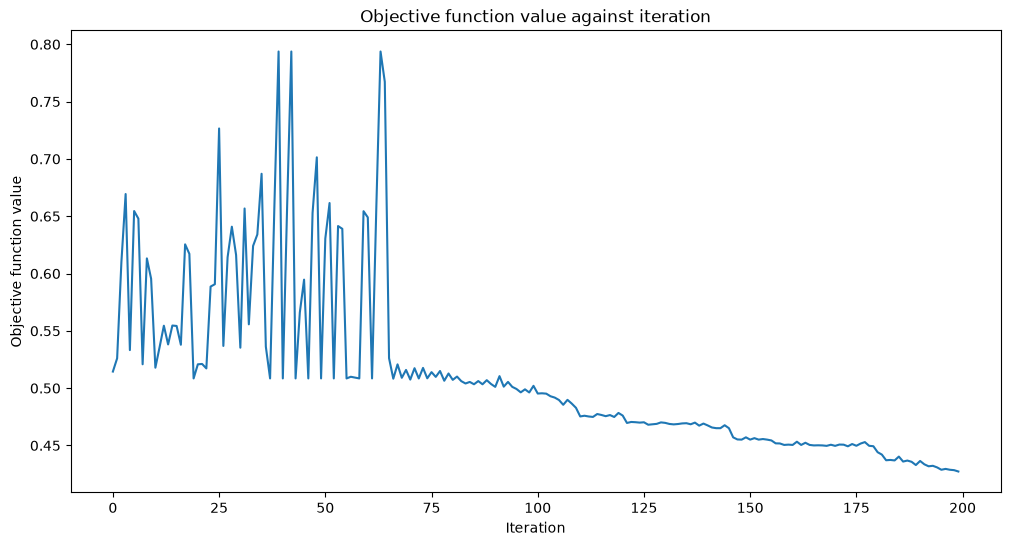

↑ training curve: mean squared error between <Z_7> and the ±1 labels of the 35 training images, one point per COBYLA iteration
objective: first 0.5145, last 0.4273 after 200 evaluations
Accuracy from the train data : 97.14%


In [14]:
x = np.asarray(train_images)                        # (35, 8) array: one row per image
y = np.asarray(train_labels)                        # (35,) array of ±1

objective_func_vals = []                            # filled by callback_graph
plt.rcParams["figure.figsize"] = (12, 6)
classifier.fit(x, y)                                # the training: COBYLA minimises the loss over the 63 weights

print("↑ training curve: mean squared error between <Z_7> and the ±1 labels of the 35 training images, one point per COBYLA iteration")
print(f"objective: first {objective_func_vals[0]:.4f}, last {objective_func_vals[-1]:.4f} after {len(objective_func_vals)} evaluations")
# score classifier
print(f"Accuracy from the train data : {np.round(100 * classifier.score(x, y), 2)}%")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `classifier.fit(x, y)` | runs the optimizer: every step binds the weights, evaluates ⟨Z₇⟩ for the 35 images with the exact estimator and computes the loss |
| `objective_func_vals[0]`, `[-1]` | loss at the pre-trained starting point and after the last iteration |
| `classifier.score(x, y)` | fraction of images whose predicted class sign⟨Z₇⟩ equals the label (scikit-learn's accuracy) |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The loss being minimised.** With the default squared-error loss, NeuralNetworkClassifier minimises

$$L(w)=\frac{1}{35}\sum_{i=1}^{35}\big(f(x_i,w)-y_i\big)^2,\qquad f=\langle Z_7\rangle\in[-1,1],\ y_i=\pm1 ,$$

so $0\le L\le4$, and a network that always answers $f=0$ scores $L=1$. Each term is at most $1$ when the sign is right, so $L<1$ does
not yet mean every image is classified correctly — accuracy only looks at the sign. The cell prints
`objective: first 0.5145, last 0.4273` and a training accuracy of `97.14%` (34 of 35 images). The spikes in the first ~64 points are COBYLA probing the 63 weight directions one by one to build its linear model (every point is one loss evaluation, not an accepted step); after that the loss decreases steadily from about $0.51$: the pre-trained start was already a good point, and 200 evaluations are not yet converged.

</details>


As we can see from above, the QCNN converges slowly, hence our `initial_point` was already close to an optimal solution. The next step is to determine whether our QCNN can classify data seen in our test image data set. 

## 6. Testing our QCNN

After building and training our dataset we now test whether our QCNN can predict images that are not from our test data set. 

Accuracy from the test data : 86.67%


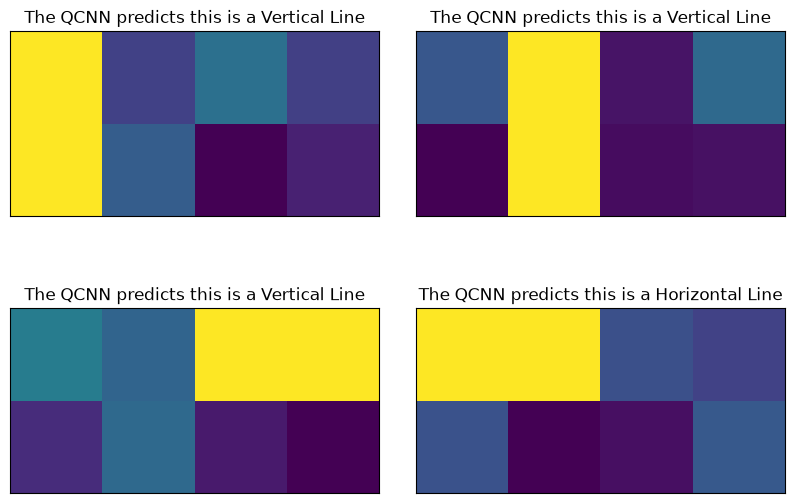

↑ four test images with the QCNN's prediction as title; true labels: [1, 1, -1, -1]


In [15]:
y_predict = classifier.predict(test_images)         # sign of <Z_7> for each of the 15 test images
x = np.asarray(test_images)                         # NB: x, y now hold the TEST set
y = np.asarray(test_labels)
print(f"Accuracy from the test data : {np.round(100 * classifier.score(x, y), 2)}%")

# Let's see some examples in our dataset
fig, ax = plt.subplots(2, 2, figsize=(10, 6), subplot_kw={"xticks": [], "yticks": []})
for i in range(0, 4):
    ax[i // 2, i % 2].imshow(test_images[i].reshape(2, 4), aspect="equal")
    if y_predict[i] == -1:
        ax[i // 2, i % 2].set_title("The QCNN predicts this is a Horizontal Line")
    if y_predict[i] == +1:
        ax[i // 2, i % 2].set_title("The QCNN predicts this is a Vertical Line")
plt.subplots_adjust(wspace=0.1, hspace=0.5)
plt.show()
print("↑ four test images with the QCNN's prediction as title; true labels:", test_labels[:4])


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `classifier.predict(test_images)` | evaluates the trained QNN on unseen images and returns sign⟨Z₇⟩ ∈ {−1, +1} |
| `classifier.score(x, y)` | test accuracy: the honest measure of what the network learned (the test images were never used in training) |
| `set_title(...)` | writes the prediction above each picture; compare with the printed true labels |

</details>


From above, we can indeed see that our QCNN can classify horizontal and vertical lines! Congratulations! Through the use of quantum circuits and quantum convolutional and pooling layers, you have built a Quantum Convolutional Neural Network! 

## 6b. (Optional) Training the QCNN on IBM Quantum hardware

The author's last cells repeat the training on a real IBM QPU through Qiskit Runtime: choose the least-busy backend with at
least 8 qubits, transpile the decomposed QCNN for it (`generate_preset_pass_manager`, optimization level 3), wrap a Runtime
`EstimatorV2` in an `EstimatorQNN` and fit it with COBYLA (100 iterations) inside a `Session`.

**Cost warning.** Every COBYLA iteration evaluates the 35 training images: 100 iterations are 3 500 circuit evaluations of
a circuit with more than 50 two-qubit gates (after routing). This is the slow, expensive part of quantum machine learning on
hardware; it is a demonstration, not something to run casually. A `Session` also needs a paid (non-open) plan.

Without a saved IBM Quantum account (`QiskitRuntimeService.save_account(...)`) these cells print a message and are skipped;
nothing else in the notebook depends on them. Compared with the original cells, the code was made runnable: the Runtime
estimator is imported (`EstimatorV2`), the undefined `n_qubit` and `transpiled_circuit_dcmp` are defined, the observable is
mapped onto the transpiled layout, and the hardware model is trained on the *training* set and stored in new variables
(`qnn_hw`, `classifier_hw`) so that the simulator results above are not overwritten.


In [16]:
def get_least_busy_backend(service, min_qubits=4):
    """
    Get the least busy backend that meets the minimum qubit requirement.

    Args:
        service: QiskitRuntimeService instance
        min_qubits (int): Minimum number of qubits required

    Returns:
        str: Name of the least busy backend
    """
    backends = service.backends()                   # every backend this account can use

    # Filter backends based on criteria
    filtered_backends = []
    for backend in backends:
        # Check if backend meets our requirements
        if (backend.status().operational and  # Backend is operational
            backend.status().pending_jobs is not None and  # Queue information is available
            backend.num_qubits >= min_qubits):  # Has enough qubits
            filtered_backends.append(backend)

    if not filtered_backends:
        raise ValueError(f"No available backend with at least {min_qubits} qubits")

    # Sort by number of pending jobs
    least_busy = sorted(filtered_backends,
                       key=lambda x: x.status().pending_jobs)[0]   # key=lambda: sort by queue length; [0] = shortest queue

    return least_busy.name


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `service.backends()`, `backend.status()` | Qiskit Runtime: the list of QPUs of the account and their live status (operational, jobs in the queue) |
| `sorted(..., key=lambda x: x.status().pending_jobs)[0]` | the backend with the shortest queue; `lambda` is an inline one-line function |
| only a definition | nothing is contacted until the function is called below |

</details>


In [17]:
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler, OptionsV2 as Options, Session   # IBM cloud access
from qiskit_ibm_runtime import EstimatorV2 as RuntimeEstimator   # the hardware estimator (StatevectorEstimator cannot run on a QPU)
from qiskit.transpiler import PassManager
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # transpiler: circuit -> backend gates and qubits


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QiskitRuntimeService`, `Session` | the account / cloud connection, and a reserved window on one QPU for a sequence of related jobs (an optimisation loop) |
| `EstimatorV2 as RuntimeEstimator` | the Runtime version of the Estimator primitive: ⟨O⟩ estimated from shots on the QPU, with error mitigation options |
| `generate_preset_pass_manager` | builds the transpiler pipeline for a given backend target |

</details>


In [18]:
try:
    service = QiskitRuntimeService()                # reads the account saved with QiskitRuntimeService.save_account(...)
except Exception as err:                            # no saved account / no network: skip the hardware part
    service = None
    print(f"No IBM Quantum account available ({type(err).__name__}): the hardware cells below are skipped.")


No IBM Quantum account available (AccountNotFoundError): the hardware cells below are skipped.


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QiskitRuntimeService()` | logs in with the credentials saved on this computer |
| `try: ... except Exception` | without an account the constructor raises; here it prints a message and sets `service = None`, which the next cells test |

</details>


In [19]:
backend_name = None
if service is not None:
    try:
        backend_name = get_least_busy_backend(service, min_qubits=circuit.num_qubits)   # the QCNN needs 8 qubits (the original used an undefined n_qubit)
        print(f"\nSelected least busy backend: {backend_name}")
    except ValueError as e:
        print(f"Error: {e}")                        # (the original called exit(1), which would stop the notebook kernel)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `min_qubits=circuit.num_qubits` | 8: one qubit per pixel |
| `backend_name = None` | stays None when there is no account or no suitable QPU: the following cells then do nothing |

</details>


In [20]:
if backend_name is not None:
    backend = service.backend(backend_name)

    # Create a pass manager with optimization level 3
    pass_manager = generate_preset_pass_manager(
        optimization_level=3,
        target=backend.target
    )
    transpiled_circuit_dcmp = pass_manager.run(circuit.decompose())   # the QCNN in the QPU's native gates, on physical qubits
    observable_hw = observable.apply_layout(transpiled_circuit_dcmp.layout)   # Z on the physical qubit that now holds logical qubit 7
    print("transpiled QCNN:", dict(transpiled_circuit_dcmp.count_ops()), "| depth:", transpiled_circuit_dcmp.depth())


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `generate_preset_pass_manager(optimization_level=3, target=backend.target)` | the heaviest optimisation: routing on the QPU's coupling map and translation to its native gates |
| `observable.apply_layout(layout)` | the transpiled circuit lives on physical qubits (e.g. 127), so the 8-qubit observable must be widened and re-indexed to match |
| `count_ops()`, `depth()` | the cost of one evaluation on the real chip |

</details>


In [21]:
def callback_graph(weights, obj_func_eval):          # same live plot as before, for the hardware run
    clear_output(wait=True)
    objective_func_vals.append(obj_func_eval)
    plt.title("Objective function value against iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Objective function value")
    plt.plot(range(len(objective_func_vals)), objective_func_vals)
    plt.show()


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `callback_graph` | redefined identically for the hardware training (the author's cell) |

</details>


In [22]:
if backend_name is not None:
    x_train, y_train = np.asarray(train_images), np.asarray(train_labels)   # train on the TRAINING set (x, y now hold the test set)
    objective_func_vals = []
    with Session(backend=backend) as session:      # all the jobs of the optimisation share one reserved QPU window
        estimator_hw = RuntimeEstimator(mode=session)#, options=options)
        qnn_hw = EstimatorQNN(
            circuit=transpiled_circuit_dcmp,
            estimator=estimator_hw,
            observables=observable_hw,
            input_params=feature_map.parameters,
            weight_params=ansatz.parameters,
        )

        classifier_hw = NeuralNetworkClassifier(
            qnn_hw,
            optimizer=COBYLA(maxiter=100),  # Set max iterations here
            callback=callback_graph,
        )

        classifier_hw.fit(x_train, y_train)        # 100 iterations x 35 images on the QPU: slow and costly

        # score classifier
        print(f"Accuracy from the train data : {np.round(100 * classifier_hw.score(x_train, y_train), 2)}%")

        y_predict_hw = classifier_hw.predict(test_images)
else:
    print("Hardware training skipped (no IBM Quantum account / backend).")


Hardware training skipped (no IBM Quantum account / backend).


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `with Session(backend=backend) as session` | opens a session; on the open (free) plan use `RuntimeEstimator(mode=backend)` instead — sessions are not available there |
| `EstimatorQNN(circuit=transpiled_circuit_dcmp, observables=observable_hw, ...)` | the same network, but evaluated by the QPU: outputs are shot estimates of ⟨Z₇⟩, with noise |
| `classifier_hw.fit(x_train, y_train)` | training from random initial weights (no `initial_point`): the author's choice, so many iterations are needed |
| `else: print(...)` | without an account the cell only prints a message |

</details>


## 🔬 In-depth analysis

1. **The convolution block as $N(\alpha,\beta,\gamma)$.** For three random angle triples $\theta\in[0,\pi/2]^3$ compute the Weyl
   coordinates of `conv_circuit(θ)` with `qiskit.synthesis.TwoQubitWeylDecomposition` and compare them with
   $(\pi/4-\theta_0/2,\ \pi/4-\theta_1/2,\ \theta_2/2-\pi/4)$ from the box of Section 2.1 (up to the ordering and signs fixed by the
   canonical Weyl chamber). Which $\theta$ makes the block non-entangling?
2. **A bigger QCNN.** Check $P_{\rm conv}(n)=3n$ and $P_{\rm pool}(n)=3n/2$ for $n=2,4,8,16$ by building the layers, then build a
   16-qubit QCNN ($16\to8\to4\to2\to1$, four convolution and four pooling layers) and compare its number of weights with your
   prediction. Which qubit is the readout qubit?
3. **Margins and robustness.** Compute the outputs $\langle Z_7\rangle$ of the trained network on the 15 test images
   (`qnn.forward`) and find the smallest margin $|\langle Z_7\rangle|$. Then take 40 fresh images, redraw their background
   noise uniformly in $[0,a]$ for $a=\pi/4$ (the training level), $3\pi/8$ and $\pi/2$, and measure the accuracy of the trained
   classifier. Use the box of the feature map to explain the trend.

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [23]:
# 🔬 In-depth analysis — your code here



In [24]:
# Reference solution
from qiskit.synthesis import TwoQubitWeylDecomposition   # KAK / Weyl decomposition of a 2-qubit unitary
from qiskit.quantum_info import Operator                  # the 4x4 matrix of a circuit

# (1) Weyl coordinates of the convolution block vs the formula of Section 2.1
rng_w = np.random.default_rng(11)
for th in list(rng_w.uniform(0, np.pi / 2, size=(3, 3))) + [np.full(3, np.pi / 2)]:   # 3 random triples + θ = (π/2, π/2, π/2)
    weyl = TwoQubitWeylDecomposition(Operator(conv_circuit(th)).data)               # canonical (a, b, c) with π/4 >= a >= b >= |c|
    pred = (np.pi / 4 - th[0] / 2, np.pi / 4 - th[1] / 2, th[2] / 2 - np.pi / 4)    # the formula of the box
    same = np.allclose(sorted(np.abs([weyl.a, weyl.b, weyl.c])), sorted(np.abs(pred)), atol=1e-7)   # compare up to order and signs
    print(f"(1) θ = {np.round(th, 3)}: Weyl (a, b, c) = {np.round([weyl.a, weyl.b, weyl.c], 4)}, formula {np.round(pred, 4)} -> match: {same}")
print("    θ = (π/2, π/2, π/2) gives (0, 0, 0): the block is a product of single-qubit gates (no entanglement)")

# (2) parameter counting and a 16-qubit QCNN (circuit construction only, nothing is simulated)
for n in (2, 4, 8, 16):
    pc, pp = conv_layer(n, "c").num_parameters, pool_layer(list(range(n // 2)), list(range(n // 2, n)), "p").num_parameters
    print(f"(2) n = {n:2d}: conv {pc:2d} (3n = {3 * n:2d}), pool {pp:2d} (3n/2 = {3 * n // 2:2d})")
ansatz16, active = QuantumCircuit(16), list(range(16))     # 'active' = the qubits still in use
for k in range(4):                                         # 16 -> 8 -> 4 -> 2 -> 1
    m = len(active)
    ansatz16.compose(conv_layer(m, f"c{k}"), active, inplace=True)
    ansatz16.compose(pool_layer(list(range(m // 2)), list(range(m // 2, m)), f"p{k}"), active, inplace=True)
    active = active[m // 2:]                               # the sinks survive
pred16 = 3 * (16 + 8 + 4 + 2) + 3 * (8 + 4 + 2 + 1)
print(f"    16-qubit QCNN: {ansatz16.num_parameters} weights (prediction 3·30 + 3·15 = {pred16}); readout qubit {active[0]}")

# (3) margins on the test set and robustness to stronger background noise
z_test = qnn.forward(np.asarray(test_images), classifier.weights).ravel()   # exact <Z_7> for the 15 test images
print(f"(3) test outputs <Z_7>: {np.round(np.sort(z_test), 3)}")
print(f"    smallest margin |<Z_7>| = {np.abs(z_test).min():.3f}; accuracy {np.mean(np.sign(z_test) == np.asarray(test_labels)):.0%}")
rng_n = np.random.default_rng(7)
fresh, fresh_labels = generate_dataset(40)                 # 40 new images (the library's seeded generator continues)
for a_max in (np.pi / 4, 3 * np.pi / 8, np.pi / 2):
    noisy = []
    for img in fresh:
        img = np.array(img)                                # copy
        bg = img != np.pi / 2                              # background pixels (the line pixels are exactly π/2)
        img[bg] = rng_n.uniform(0, a_max, size=bg.sum())   # redraw the noise in [0, a_max]
        noisy.append(img)
    acc = classifier.score(np.asarray(noisy), np.asarray(fresh_labels))
    print(f"    noise in [0, {a_max / np.pi:.3f}π]: max P(1) of a background qubit = sin²(a) = {np.sin(a_max) ** 2:.3f}, accuracy {acc:.0%}")


(1) θ = [0.202 0.784 0.945]: Weyl (a, b, c) = [ 0.6844  0.3933 -0.313 ], formula [ 0.6844  0.3933 -0.313 ] -> match: True
(1) θ = [0.045 0.232 1.458]: Weyl (a, b, c) = [ 0.7629  0.6692 -0.0564], formula [ 0.7629  0.6692 -0.0564] -> match: True
(1) θ = [0.111 0.204 1.49 ]: Weyl (a, b, c) = [ 0.7301  0.6835 -0.0406], formula [ 0.7301  0.6835 -0.0406] -> match: True
(1) θ = [1.571 1.571 1.571]: Weyl (a, b, c) = [0. 0. 0.], formula [0. 0. 0.] -> match: True
    θ = (π/2, π/2, π/2) gives (0, 0, 0): the block is a product of single-qubit gates (no entanglement)
(2) n =  2: conv  6 (3n =  6), pool  3 (3n/2 =  3)
(2) n =  4: conv 12 (3n = 12), pool  6 (3n/2 =  6)
(2) n =  8: conv 24 (3n = 24), pool 12 (3n/2 = 12)
(2) n = 16: conv 48 (3n = 48), pool 24 (3n/2 = 24)
    16-qubit QCNN: 135 weights (prediction 3·30 + 3·15 = 135); readout qubit 15
(3) test outputs <Z_7>: [-0.755 -0.553 -0.413 -0.206 -0.003  0.04   0.04   0.208  0.214  0.245
  0.304  0.304  0.333  0.381  0.525]
    smallest margin |<

    noise in [0, 0.250π]: max P(1) of a background qubit = sin²(a) = 0.500, accuracy 80%
    noise in [0, 0.375π]: max P(1) of a background qubit = sin²(a) = 0.854, accuracy 45%


    noise in [0, 0.500π]: max P(1) of a background qubit = sin²(a) = 1.000, accuracy 55%


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `TwoQubitWeylDecomposition(U)` | writes U = (K₁⊗K₂)·exp(i(a XX + b YY + c ZZ))·(K₃⊗K₄) with canonical a ≥ b ≥ \|c\|: the non-local content of the block |
| `sorted(np.abs(...))` | the canonical chamber may reorder the coordinates and flip pairs of signs (both are local operations), so the comparison ignores order and signs |
| `active = active[m // 2:]` | after each pooling only the sinks (second half of the active qubits) stay active: 16 → 8 → 4 → 2 → 1 |
| `qnn.forward(X, classifier.weights)` | the raw network output ⟨Z₇⟩ for a batch of images with the trained weights; its sign is the prediction, its size the margin |
| `img[bg] = rng_n.uniform(0, a_max, ...)` | boolean-mask assignment: only background pixels get new noise; as a → π/2 the noise can reach the line value, P(1) = sin²a → 1, and lines become ambiguous |

</details>


## 7. References

[1] Cong, I., Choi, S. & Lukin, M.D. Quantum convolutional neural networks. Nat. Phys. 15, 1273–1278 (2019). https://doi.org/10.1038/s41567-019-0648-8

[2] IBM Convolutional Neural Networks https://www.ibm.com/cloud/learn/convolutional-neural-networks

[3] Vatan, Farrokh, and Colin Williams. "Optimal quantum circuits for general two-qubit gates." Physical Review A 69.3 (2004): 032315.

In [25]:
# The original tutorial ended with `import tutorial_magics` and %qiskit_version_table, helpers that exist only in the
# Qiskit documentation build; this prints the versions the notebook was run with instead.
import sys, sklearn
print("python", sys.version.split()[0], "| qiskit", qiskit.__version__,
      "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| scikit-learn", sklearn.__version__)


python 3.13.14 | qiskit 2.1.2 | qiskit-machine-learning 0.9.1 | scikit-learn 1.9.0


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `sys.version`, `__version__` | the software versions: results of QML tutorials depend on them (optimizer defaults, primitives) |

</details>
